In [22]:
import numpy as np
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [23]:
# Loading dataset
# MNIST = Modified National Institute of Standards and Technology

(X_train, y_train), (X_test, y_test) = keras.datasets.mnist.load_data()

print(f'Train shape: {X_train.shape}')
print(f'Test shape: {X_test.shape}')

Train shape: (60000, 28, 28)
Test shape: (10000, 28, 28)


In [24]:
# Preprocessing pixels to 0-1

X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0


# Reshaping the dimension to (height, width, channels)

X_train = X_train.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)

In [25]:
# Building CNN model

model = keras.Sequential([

    # Image shape is 28x28 with 1=grayscale
    layers.Input(shape=(28, 28, 1)),

    # First Layer
    # 32 filters of 3x3
    layers.Conv2D(32, kernel_size=(3,3), activation='relu'),

    # First Max Pooling Layer
    layers.MaxPooling2D(pool_size=(2,2)),

    # Second Layer
    # 64 filters of 3x3
    layers.Conv2D(64, kernel_size=(3,3), activation='relu'),

    # Second Max Pooling Layer
    layers.MaxPooling2D(pool_size=(2,2)),

    # Converting 2D feature maps to 1D
    layers.Flatten(),

    # Random dropping of 30% neurons
    layers.Dropout(0.3),

    # Creating a Dense Hidden Layer of 64 neurons
    layers.Dense(64, activation='relu'),

    # Output Layer
    # 10 neurons as 0 to 9
    layers.Dense(10, activation='softmax')
])

# Compiling the model
model.compile(
    optimizer='adam', #Optimizer
    loss='sparse_categorical_crossentropy', # Loss function 
    metrics=['accuracy'] # Evaluating
)

# Summary of model
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━┳━━━━━━━━━━━┳━━━━━━━┓
┃               ┃ Output    ┃ Param ┃
┃ Layer (type)  ┃ Shape     ┃     # ┃
┡━━━━━━━━━━━━━━━╇━━━━━━━━━━━╇━━━━━━━┩
│ conv2d_4      │ (None,    │   320 │
│ (Conv2D)      │ 26, 26,   │       │
│               │ 32)       │       │
├───────────────┼───────────┼───────┤
│ max_pooling2… │ (None,    │     0 │
│ (MaxPooling2… │ 13, 13,   │       │
│               │ 32)       │       │
├───────────────┼───────────┼───────┤
│ conv2d_5      │ (None,    │ 18,4… │
│ (Conv2D)      │ 11, 11,   │       │
│               │ 64)       │       │
├───────────────┼───────────┼───────┤
│ max_pooling2… │ (None, 5, │     0 │
│ (MaxPooling2… │ 5, 64)    │       │
├───────────────┼───────────┼───────┤
│ flatten_2     │ (None,    │     0 │
│ (Flatten)     │ 1600)     │       │
├───────────────┼───────────┼───────┤
│ dropout_2     │ (None,    │     0 │
│ (Dropout)     │ 1600)     │       │
├───────────────┼───────────┼───────┤
│ dense_4       │ (None,    │ 102,… │
│ (Dense)       │ 64)       │       │
├───────────────┼───────────┼───────┤
│ dense_5       │ (None,    │   650 │
│ (Dense)       │ 10)       │       │
└───────────────┴───────────┴───────┘

 Total params: 121,930 (476.29 KB)

 Trainable params: 121,930 (476.29 KB)

 Non-trainable params: 0 (0.00 B)

In [26]:
# Training model

h = model.fit(
    X_train, 
    y_train,
    validation_split=0.1,
    epochs =10,
    batch_size = 64, 
    verbose =1
)

Epoch 1/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 14s 15ms/step - accuracy: 0.9356 - loss: 0.2127 - val_accuracy: 0.9820 - val_loss: 0.0589
Epoch 2/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 13s 15ms/step - accuracy: 0.9798 - loss: 0.0655 - val_accuracy: 0.9850 - val_loss: 0.0502
Epoch 3/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 16s 18ms/step - accuracy: 0.9843 - loss: 0.0494 - val_accuracy: 0.9888 - val_loss: 0.0411
Epoch 4/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 24s 29ms/step - accuracy: 0.9871 - loss: 0.0391 - val_accuracy: 0.9887 - val_loss: 0.0386
Epoch 5/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 25s 29ms/step - accuracy: 0.9896 - loss: 0.0335 - val_accuracy: 0.9913 - val_loss: 0.0321
Epoch 6/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 25s 29ms/step - accuracy: 0.9911 - loss: 0.0281 - val_accuracy: 0.9917 - val_loss: 0.0305
Epoch 7/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 24s 28ms/step - accuracy: 0.9920 - loss: 0.0250 - val_accuracy: 0.9907 - val_loss: 0.0322
Epoch 8/10
844/844 ━━━━━━━━━━━━━━━━━━━━ 24s 28ms/step - accuracy: 0.9931 - loss: 0.0214 - 

In [27]:
# Evaluating on Test

l,a = model.evaluate(X_test, y_test)

print(f'Test Accuracy: {a:.3f}')

y_proba = model.predict(X_test)
y_pred = np.argmax(y_proba, axis=1)

print(classification_report(y_test, y_pred))

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.9886 - loss: 0.0376
Test Accuracy: 0.989
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step
              precision    recall  f1-score   support

           0       0.99      1.00      0.99       980
           1       1.00      1.00      1.00      1135
           2       0.99      0.99      0.99      1032
           3       0.97      1.00      0.98      1010
           4       0.99      0.99      0.99       982
           5       0.98      0.99      0.99       892
           6       1.00      0.98      0.99       958
           7       0.98      1.00      0.99      1028
           8       1.00      0.97      0.98       974
           9       0.99      0.98      0.98      1009

    accuracy                           0.99     10000
   macro avg       0.99      0.99      0.99     10000
weighted avg       0.99      0.99      0.99     10000



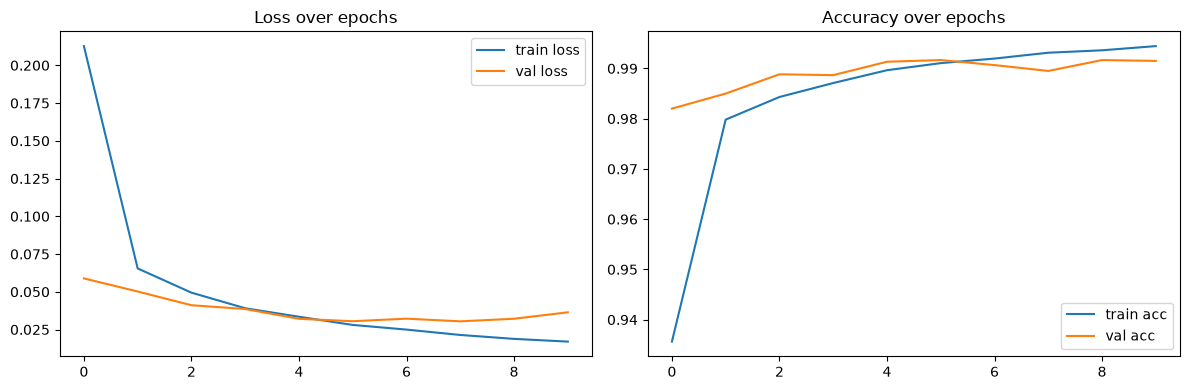

In [28]:
# Plotting the training curves

f, ax = plt.subplots(1,2, figsize=(12,4))

ax[0].plot(h.history['loss'],label='train loss')
ax[0].plot(h.history['val_loss'],label='val loss')
ax[0].set_title('Loss over epochs')
ax[0].legend()

ax[1].plot(h.history['accuracy'],label='train acc')
ax[1].plot(h.history['val_accuracy'],label='val acc')
ax[1].set_title('Accuracy over epochs')
ax[1].legend()

plt.tight_layout()
plt.show()

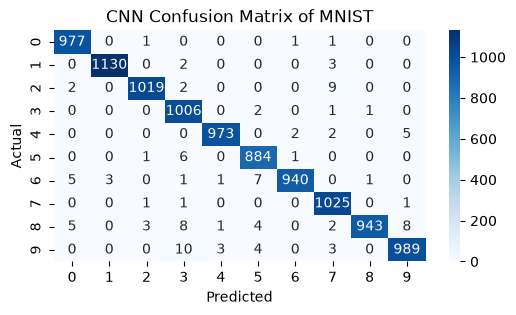

In [29]:
# Confusion matrix (which digits get confused with which)

import seaborn as sns

cm = confusion_matrix(y_test,y_pred)
plt.figure(figsize =(6,3))

sns.heatmap(cm, annot=True, fmt = 'd', cmap = 'Blues')

plt.xlabel('Predicted')
plt.ylabel('Actual')

plt.title('CNN Confusion Matrix of MNIST')
plt.show()

In [30]:
model.save('model.keras')